In [ ]:
import os

# For headless MuJoCo rendering on a remote GPU server
os.environ["MUJOCO_GL"] = "egl"

from dataclasses import dataclass, asdict
import numpy as np
import torch
import gymnasium as gym
import torch.nn as nn
from torch.distributions import Normal
from torch.functional import F
import matplotlib.pyplot as plt
import imageio.v2 as imageio
from pathlib import Path
from IPython.display import Video, display



@dataclass
class SACConfig:
    # Training
    total_timesteps: int = 100_000
    learning_starts: int = 10_000
    train_freq: int = 5
    gradient_steps: int = 1
    batch_size: int = 128
    eval_interval: int = 10_000

    # Replay buffer
    buffer_size: int = 1_000_000

    # SAC hyperparameters
    gamma: float = 0.99
    tau: float = 0.005
    learning_rate: float = 3e-4
    reward_scale: float = 1.0
    target_update_interval: int = 1

    # Network
    hidden_dim: int = 256

    # Reproducibility
    seed: int = 1012




In [3]:
class Actor(nn.Module):

    def __init__(self, obs_dim, action_dim, hidden_dim=256):
        super().__init__()

        # Shared feature extractor
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )

        # Gaussian distribution parameters
        self.mu = nn.Linear(hidden_dim, action_dim)
        self.log_std = nn.Linear(hidden_dim, action_dim)
        self.log_std_min = -20
        self.log_std_max = 2

    def forward(self, obs):
        features = self.net(obs)
        mean = self.mu(features)
        log_std = self.log_std(features)
        log_std = torch.clamp(log_std, self.log_std_min, self.log_std_max)  
        std = log_std.exp()

        return mean, std


    # Sample actions and compute log probabilities
    def actionLogProb(self, obs):

        mean, std = self.forward(obs)
        dist = Normal(mean, std)
        u = dist.rsample() # reparameterization trick for backpropagation
        action = torch.tanh(u) # action between -1 and 1

        # Calculting log \pi(a|S)
        log_prob = dist.log_prob(u)
        log_prob -= 2 * (torch.log(torch.tensor(2.0, device=u.device)) - u - nn.functional.softplus(-2 * u))
        log_prob = log_prob.sum(dim=-1, keepdim=True)

        return action, log_prob

    def predict(self, obs, deterministic=True):
        """Return normalized actions for inference."""

        mean, std = self.forward(obs)

        if deterministic:
            return torch.tanh(mean)

        dist = Normal(mean, std)
        return torch.tanh(dist.sample())


In [4]:
class Critic(nn.Module):

    def __init__(self, obs_dim, action_dim, hidden_dim=256):
        super().__init__()

        input_dim = obs_dim + action_dim

        # First Q network
        self.q1 = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

        # Second Q network
        self.q2 = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, obs, action):
        x = torch.cat([obs, action], dim=-1)
        q1 = self.q1(x)
        q2 = self.q2(x)

        return q1, q2



In [5]:
class ReplayBuffer:

    def __init__(self, buffer_size, num_envs, obs_dim, action_dim, device):

        self.num_envs = num_envs
        self.obs_dim = obs_dim
        self.action_dim = action_dim
        self.device = torch.device(device)

        # Capacity measured in vectorized steps
        self.capacity = max(buffer_size // num_envs, 1 )

        # Allocate storage
        self.obs = np.zeros((self.capacity, num_envs, obs_dim), dtype=np.float32)
        self.next_obs = np.zeros_like(self.obs)
        self.actions = np.zeros((self.capacity, num_envs, action_dim), dtype=np.float32)
        self.rewards = np.zeros((self.capacity, num_envs), dtype=np.float32)
        self.dones = np.zeros((self.capacity, num_envs), dtype=np.float32)
        self.timeouts = np.zeros_like(self.dones)

        self.pos = 0
        self.full = False

    def push(self, obs, next_obs, actions, rewards, dones, timeouts):

        self.obs[self.pos] = obs
        self.next_obs[self.pos] = next_obs
        self.actions[self.pos] = actions
        self.rewards[self.pos] = rewards
        self.dones[self.pos] = dones
        self.timeouts[self.pos] = timeouts

        # Circular buffer
        self.pos += 1
        if self.pos >= self.capacity:
            self.pos = 0
            self.full = True

    # bookkeeping, length of stored transition
    def __len__(self):
        steps = self.capacity if self.full else self.pos
        return steps * self.num_envs

    def sample(self, batch_size):

        size = self.capacity if self.full else self.pos

        if size == 0:
            raise ValueError("Cannot sample an empty buffer")

        # Random time & environment indices
        batch_indices = np.random.randint(0, size, size=batch_size)
        env_indices = np.random.randint(0, self.num_envs, size=batch_size)

        obs = self.obs[batch_indices, env_indices]
        next_obs = self.next_obs[batch_indices, env_indices]
        actions = self.actions[batch_indices, env_indices]
        rewards = self.rewards[batch_indices, env_indices].reshape(-1, 1) #reshapes into a column vector for each transition
        dones = self.dones[batch_indices, env_indices].reshape(-1, 1)
        timeouts = self.timeouts[batch_indices, env_indices].reshape(-1, 1)

        # Only true terminations stop bootstrapping
        dones = dones * (1.0 - timeouts)

        def to_tensor(x):
            return torch.as_tensor(x, dtype=torch.float32, device=self.device)

        return {
            "obs": to_tensor(obs),
            "next_obs": to_tensor(next_obs),
            "actions": to_tensor(actions),
            "rewards": to_tensor(rewards),
            "dones": to_tensor(dones)
        }


In [6]:
class SACAgent:

    def __init__(self, env, config=None, device=None):

        self.env = env
        self.config = config or SACConfig()
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu" ))

        self.num_envs = env.num_envs
        self.obs_dim = env.observation_space.shape[0]
        self.action_dim = env.action_space.shape[0]

        # Continuous action space
        assert isinstance(env.action_space, gym.spaces.Box)

        # Action bounds
        self.action_low = np.asarray(env.action_space.low, dtype=np.float32)
        self.action_high = np.asarray(env.action_space.high, dtype=np.float32)

        assert np.all(np.isfinite(self.action_low))
        assert np.all(np.isfinite(self.action_high))
        assert np.all(self.action_high > self.action_low)

        # Training counters
        self.num_timesteps = 0
        self.num_updates = 0

        # Track running returns for each parallel environment.
        self.episode_returns = np.zeros(self.num_envs, dtype=np.float64)
        self.completed_returns = []

        self.last_obs = None #current observations
        self.target_entropy = -float(self.action_dim) # SAC entropy target

        # Networks
        self.actor = Actor(obs_dim=self.obs_dim, action_dim=self.action_dim, hidden_dim=self.config.hidden_dim).to(self.device)
        self.actor_optimizer = torch.optim.Adam(self.actor.parameters(), lr=self.config.learning_rate) 

        self.critic = Critic(obs_dim=self.obs_dim, action_dim=self.action_dim, hidden_dim=self.config.hidden_dim).to(self.device)
        self.critic_target = Critic(obs_dim=self.obs_dim, action_dim=self.action_dim, hidden_dim=self.config.hidden_dim).to(self.device)

        # Initially copying online weights to target
        self.critic_target.load_state_dict(self.critic.state_dict())

        # Target network is not trained by gradient descent rather updated from online Critic using Polyak averaging
        for param in self.critic_target.parameters():
            param.requires_grad_(False)

        self.critic_optimizer = torch.optim.Adam(self.critic.parameters(), lr=self.config.learning_rate)

        self.replay_buffer = ReplayBuffer(
            buffer_size=self.config.buffer_size,
            num_envs=self.num_envs,
            obs_dim=self.obs_dim,
            action_dim=self.action_dim,
            device=self.device
        )

        # Learnable log entropy coefficient
        self.log_alpha = torch.zeros(1, device=self.device, requires_grad=True)

        # Optimizer for entropy coefficient
        self.alpha_optimizer = torch.optim.Adam([self.log_alpha], lr=self.config.learning_rate)

    
    def update_target(self):
        tau = self.config.tau
        with torch.no_grad():
            for param, target_param in zip(self.critic.parameters(), self.critic_target.parameters()):
                target_param.mul_(1 - tau)
                target_param.add_(tau * param)

    # Convert normalized actions [-1, 1] to environment bounds
    def _toEnvAction(self, action):
        return (self.action_low + 0.5 * (self.action_high - self.action_low) * (action + 1.0))

    # Convert environment actions back to [-1, 1].
    def _reverseEnvAction(self, action):
        return (2.0 * (action - self.action_low) / (self.action_high - self.action_low) - 1.0)

    
    def predict(self, obs, deterministic=True):

        obs = torch.as_tensor(obs, dtype=torch.float32, device=self.device)

        # Adds a batch dimension if the observation is a single vector
        if obs.ndim == 1:
            obs = obs.unsqueeze(0)

        self.actor.eval()

        with torch.no_grad():
            # Normalized action [-1, 1]
            action = self.actor.predict(obs, deterministic=deterministic )

        action = action.cpu().numpy()
        return self._toEnvAction(action)

    
    def _selectAction(self, obs, deterministic=False):
        
        if self.num_timesteps < self.config.learning_starts:

            # Random actions during warm-up
            action = np.random.uniform(-1.0, 1.0, size=(self.num_envs, self.action_dim)).astype(np.float32)

        else:
            env_action = self.predict(obs, deterministic=deterministic )
            # Convert back to normalized scale
            action = self._reverseEnvAction(env_action)

        return np.clip(action, -1.0, 1.0).astype(np.float32)


    # Collect transitions using vectorized environments
    def explore(self):

        if self.last_obs is None:
            self.last_obs = self.env.reset()

        collected_steps = 0

        while collected_steps < self.config.train_freq:

            # 1. Select normalized action
            buffer_actions = self._selectAction(self.last_obs, deterministic=False)
            env_actions = self._toEnvAction(buffer_actions)

            new_obs, rewards, dones, infos = self.env.step(env_actions)

            self.episode_returns += np.asarray(rewards, dtype=np.float64)
            for i in np.flatnonzero(dones):
                self.completed_returns.append(float(self.episode_returns[i]))
                self.episode_returns[i] = 0.0

            # 4. Identify time-limit truncations
            timeouts = np.array(
                [
                    info.get("TimeLimit.truncated", False)
                    for info in infos
                ],
                dtype=np.float32
            )

            # 5. Preserve actual terminal observations
            buffer_next_obs = new_obs.copy()

            for i in range(self.num_envs):
                if dones[i]:
                    buffer_next_obs[i] = infos[i][
                        "terminal_observation"
                    ]

            
            self.replay_buffer.push(
                obs=self.last_obs,
                next_obs=buffer_next_obs,
                actions=buffer_actions,
                rewards=rewards,
                dones=dones,
                timeouts=timeouts
            )

            
            self.last_obs = new_obs.copy()
            self.num_timesteps += self.num_envs
            collected_steps += self.num_envs

        return collected_steps

    
    def optimize(self):

        self.actor.train()
        self.critic.train()

        metrics = {
            "actor_loss": [],
            "critic_loss": [],
            "alpha_loss": [],
            "alpha": []
        }

        for _ in range(self.config.gradient_steps):

            # sample transitions
            batch = self.replay_buffer.sample(self.config.batch_size)

            obs = batch["obs"]
            actions = batch["actions"]
            rewards = batch["rewards"]
            next_obs = batch["next_obs"]
            dones = batch["dones"]

            # sample actions
            new_actions, log_prob = (self.actor.actionLogProb(obs) )

            # update entropy coeff
            alpha = self.log_alpha.exp().detach()
            alpha_loss = -(self.log_alpha * (log_prob + self.target_entropy).detach()).mean()
            self.alpha_optimizer.zero_grad()
            alpha_loss.backward()
            self.alpha_optimizer.step()

            # calculate target Q-values
            with torch.no_grad():

                next_actions, next_log_prob = (self.actor.actionLogProb(next_obs) )
                next_q1, next_q2 = self.critic_target(next_obs, next_actions  )
                next_q = (torch.min(next_q1, next_q2) - alpha * next_log_prob )
                target_q = (rewards * self.config.reward_scale + self.config.gamma * (1.0 - dones) * next_q )

            # update twin critic
            q1, q2 = self.critic(obs, actions)

            critic_loss = 0.5 * (F.mse_loss(q1, target_q)+ F.mse_loss(q2, target_q))
            self.critic_optimizer.zero_grad()
            critic_loss.backward()
            self.critic_optimizer.step()

            # update Actor Freezing Critic temporarily
            for param in self.critic.parameters():
                param.requires_grad_(False)

            q1_pi, q2_pi = self.critic(obs, new_actions)
            min_q_pi = torch.min(q1_pi, q2_pi)
            actor_loss = (alpha * log_prob - min_q_pi).mean()

            self.actor_optimizer.zero_grad()
            actor_loss.backward()
            self.actor_optimizer.step()

            # Restore Critic parameter gradients
            for param in self.critic.parameters():
                param.requires_grad_(True)

            # Update target networks using Polyak averaging
            self.num_updates += 1

            if (self.num_updates % self.config.target_update_interval == 0  ):
                self.update_target()

            
            metrics["actor_loss"].append(actor_loss.item())
            metrics["critic_loss"].append(critic_loss.item())
            metrics["alpha_loss"].append(alpha_loss.item())
            metrics["alpha"].append(alpha.item())

        return {key: float(np.mean(values)) for key, values in metrics.items()}

    
    def evaluate(self, eval_env, eval_num=1, seed=None):
        """
        Evaluate deterministic policy.

        eval_env must use Xu's vectorized environment API.
        eval_num: episodes evaluated per parallel environment.
        """

        if eval_num < 1:
            raise ValueError("eval_num must be >= 1")

        if eval_env is self.env:
            raise ValueError("Evaluation environment must be separate from the training environment.")

        self.actor.eval()

        num_envs = eval_env.num_envs
        all_returns = []

        for episode in range(eval_num):

            if seed is not None:
                eval_env.seed(seed + episode * num_envs)

            obs = eval_env.reset()

            episode_returns = np.zeros(num_envs, dtype=np.float64)

            # Track which environments have finished
            finished = np.zeros(num_envs, dtype=bool)

            while not np.all(finished):

                actions = self.predict(obs, deterministic=True )
                obs, rewards, dones, infos = eval_env.step(actions)    
                episode_returns[~finished] += rewards[~finished]
                finished |= dones

            all_returns.extend(episode_returns.tolist())

        return float(np.mean(all_returns))

    
    def train(self, eval_env=None, eval_num=1):

        self.env.seed(self.config.seed)
        self.last_obs = self.env.reset()

        # Reset counters and reward tracking
        self.num_timesteps = 0
        self.num_updates = 0

        self.episode_returns.fill(0.0)
        self.completed_returns.clear()

        # Evaluation tracking
        best_eval_reward = float("-inf")

        next_eval_step = self.config.eval_interval

        training_history = []
        while self.num_timesteps < self.config.total_timesteps:
            collected_steps = self.explore()

            
            metrics = None

            if (
                self.num_timesteps >= self.config.learning_starts
                and len(self.replay_buffer) >= self.config.batch_size
            ):

                metrics = self.optimize()

            
            if metrics is not None:
                metrics["timesteps"] = self.num_timesteps
                training_history.append(metrics)

            
            if (
                eval_env is not None
                and self.num_timesteps >= next_eval_step
            ):

                eval_reward = self.evaluate(eval_env, eval_num=eval_num  )
                print(f"Steps: {self.num_timesteps} | Eval reward: {eval_reward:.2f}")

                
                if eval_reward > best_eval_reward:
                    best_eval_reward = eval_reward

                    print(f"New best reward: {best_eval_reward:.2f}")

                # Advance evaluation threshold
                while next_eval_step <= self.num_timesteps:
                    next_eval_step += self.config.eval_interval

        print("Training completed!")

        return training_history

    
    def save(self, path):

        torch.save({
            "actor": self.actor.state_dict(),
            "critic": self.critic.state_dict(),
            "critic_target": self.critic_target.state_dict(),

            "actor_optimizer": self.actor_optimizer.state_dict(),
            "critic_optimizer": self.critic_optimizer.state_dict(),

            "log_alpha": self.log_alpha.detach().cpu(),
            "alpha_optimizer": self.alpha_optimizer.state_dict(),

            "num_timesteps": self.num_timesteps,
            "num_updates": self.num_updates,

            "config": asdict(self.config)
        }, path)
    

    def load(self, path):

        checkpoint = torch.load(
            path,
            map_location=self.device,
            weights_only=True
        )

        self.actor.load_state_dict(checkpoint["actor"])
        self.critic.load_state_dict(checkpoint["critic"])
        self.critic_target.load_state_dict(
            checkpoint["critic_target"]
        )

        self.actor_optimizer.load_state_dict(
            checkpoint["actor_optimizer"]
        )
        self.critic_optimizer.load_state_dict(
            checkpoint["critic_optimizer"]
        )

        with torch.no_grad():
            self.log_alpha.copy_(
                checkpoint["log_alpha"].to(self.device)
            )

        self.alpha_optimizer.load_state_dict(
            checkpoint["alpha_optimizer"]
        )

        self.num_timesteps = checkpoint["num_timesteps"]
        self.num_updates = checkpoint["num_updates"]







In [8]:

class makeVecEnv:
    def __init__(self, env_fns):
        self.envs = [fn() for fn in env_fns]
        self.num_envs = len(self.envs)
        self.observation_space = self.envs[0].observation_space
        self.action_space = self.envs[0].action_space

    def seed(self, seed):
        self._seed = seed

    def reset(self):
        observations = []
        for i, env in enumerate(self.envs):
            seed = getattr(self, "_seed", None)
            obs, _ = env.reset(
                seed=None if seed is None else seed + i
            )
            observations.append(obs)
        self._seed = None
        return np.stack(observations).astype(np.float32)

    def step(self, actions):
        observations, rewards, dones, infos = [], [], [], []

        for env, action in zip(self.envs, actions):
            obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            info = dict(info)
            info["TimeLimit.truncated"] = truncated and not terminated

            if done:
                info["terminal_observation"] = obs.copy()
                obs, _ = env.reset()

            observations.append(obs)
            rewards.append(reward)
            dones.append(done)
            infos.append(info)

        return (
            np.stack(observations).astype(np.float32),
            np.asarray(rewards, dtype=np.float32),
            np.asarray(dones, dtype=bool),
            infos
        )

    def close(self):
        for env in self.envs:
            env.close()


In [16]:
SEED = 2026
NUM_ENVS = 16
RUN_DIR = Path("hopper_sac_results")
RUN_DIR.mkdir(exist_ok=True, parents=True)


np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def make_hopper():
    return gym.make("Hopper-v5")

train_env = makeVecEnv([make_hopper for _ in range(NUM_ENVS)])
eval_env = makeVecEnv([make_hopper])

config = SACConfig(
    total_timesteps=1_000_000,      # Increase to 1_000_000 for longer training
    learning_starts=10_000,
    eval_interval=10_000,
    train_freq=4,
    gradient_steps=1,
    batch_size=256,
    buffer_size=1_000_000,
    seed=SEED,
)

# config = SACConfig()

agent = SACAgent(env=train_env, config=config)
print("Device:", agent.device)
print("Observation size:", agent.obs_dim)
print("Action size:", agent.action_dim)

Device: cuda
Observation size: 11
Action size: 3


In [ ]:
try:
    history = agent.train(eval_env=eval_env, eval_num=3)
    agent.save(str(RUN_DIR / "hopper_sac_final.pt"))
    print("Final checkpoint:", RUN_DIR / "hopper_sac_final.pt")
finally:
    train_env.close()
    eval_env.close()

print("Finished training episodes:", len(agent.completed_returns))
print("Optimization records:", len(history))

Steps: 10000 | Eval reward: 40.53
New best reward: 40.53
Steps: 20000 | Eval reward: 82.81
New best reward: 82.81
Steps: 30000 | Eval reward: 54.15
Steps: 40000 | Eval reward: 180.74
New best reward: 180.74
Steps: 50000 | Eval reward: 176.01
Steps: 60000 | Eval reward: 171.19
Steps: 70000 | Eval reward: 174.23
Steps: 80000 | Eval reward: 192.94
New best reward: 192.94
Steps: 90000 | Eval reward: 227.82
New best reward: 227.82
Steps: 100000 | Eval reward: 233.80
New best reward: 233.80
Steps: 110000 | Eval reward: 260.11
New best reward: 260.11
Steps: 120000 | Eval reward: 280.26
New best reward: 280.26
Steps: 130000 | Eval reward: 264.80
Steps: 140000 | Eval reward: 357.97
New best reward: 357.97
Steps: 150000 | Eval reward: 490.49
New best reward: 490.49
Steps: 160000 | Eval reward: 377.17
Steps: 170000 | Eval reward: 498.22
New best reward: 498.22
Steps: 180000 | Eval reward: 523.99
New best reward: 523.99
Steps: 190000 | Eval reward: 297.03
Steps: 200000 | Eval reward: 312.48
Steps:

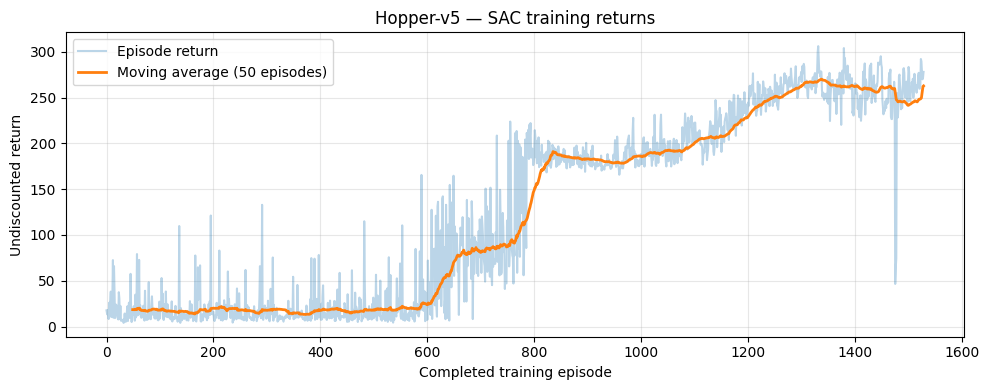

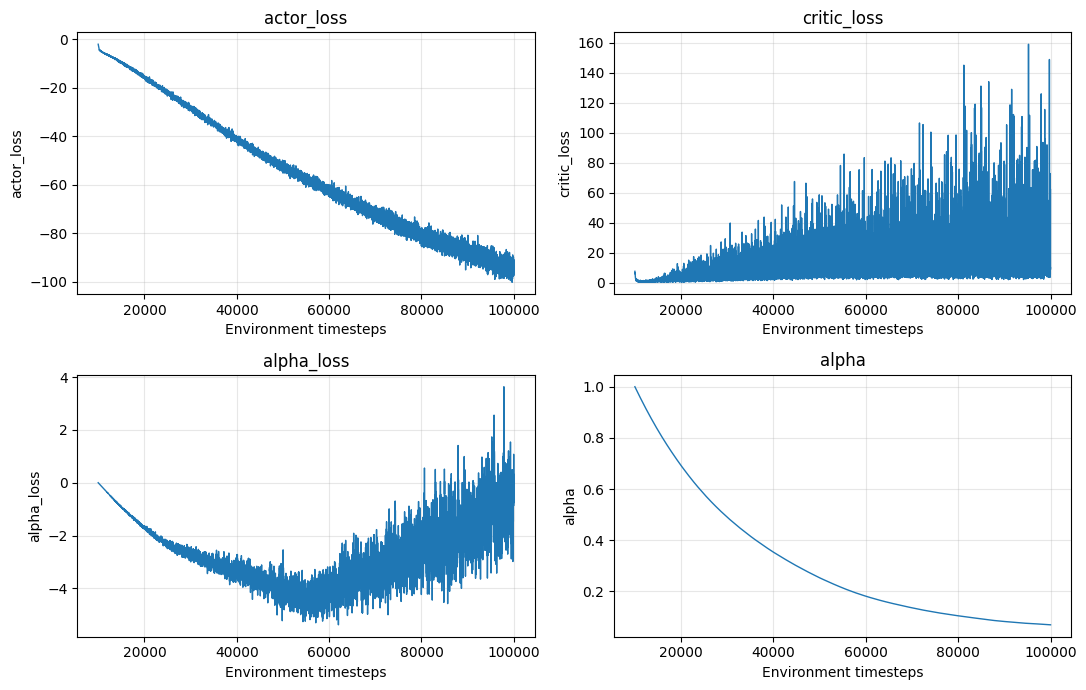

In [11]:
# 7. Visualize episode returns and optimization metrics
returns = np.asarray(agent.completed_returns, dtype=np.float64)
fig, ax = plt.subplots(figsize=(10, 4))
if len(returns):
    ax.plot(returns, alpha=0.3, label="Episode return")
    window = min(50, len(returns))
    smoothed = np.convolve(returns, np.ones(window)/window, mode="valid")
    ax.plot(np.arange(window-1, len(returns)), smoothed,
            linewidth=2, label=f"Moving average ({window} episodes)")
ax.set(xlabel="Completed training episode", ylabel="Undiscounted return",
       title="Hopper-v5 — SAC training returns")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(RUN_DIR / "episode_returns.png", dpi=160)
plt.show()

if history:
    fig, axs = plt.subplots(2, 2, figsize=(11, 7))
    keys = ["actor_loss", "critic_loss", "alpha_loss", "alpha"]
    steps = [row["timesteps"] for row in history]
    for ax, key in zip(axs.flat, keys):
        ax.plot(steps, [row[key] for row in history], linewidth=1)
        ax.set(xlabel="Environment timesteps", ylabel=key, title=key)
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(RUN_DIR / "optimization_metrics.png", dpi=160)
    plt.show()

In [12]:
# 8. Optionally reload the saved policy (for a fresh notebook session)
checkpoint_path = RUN_DIR / "hopper_sac_final.pt"
if checkpoint_path.exists():
    inference_env = makeVecEnv([make_hopper])
    inference_agent = SACAgent(inference_env, config=SACConfig(**config.__dict__))
    inference_agent.load(str(checkpoint_path))
    inference_env.close()
else:
    # Can be useful if training is still underway in this kernel
    inference_agent = agent
print("Inference policy ready")

Inference policy ready


In [ ]:

# Create output directory
VIDEO_DIR = Path("./videos")
VIDEO_DIR.mkdir(exist_ok=True)

# Headless rendering environment
env = gym.make(
    "Hopper-v5",
    render_mode="rgb_array"
)

obs, info = env.reset(seed=42)
frames = []
total_reward = 0.0

fps = round(1.0 / env.unwrapped.dt)

for step in range(1000):

    # Use the trained policy from your notebook
    action = inference_agent.predict(
        obs[None, :],
        deterministic=True
    )[0]

    obs, reward, terminated, truncated, info = (
        env.step(action)
    )

    frame = env.render()
    frames.append(frame)

    total_reward += reward

    if terminated or truncated:
        break

env.close()

# Save MP4
video_path = VIDEO_DIR / "hopper_sac.mp4"

imageio.mimsave(
    str(video_path),
    frames,
    fps=fps,
    macro_block_size=16
)

print(f"Episode reward: {total_reward:.2f}")
print(f"Video saved: {video_path.resolve()}")

# Display inside Jupyter
display(Video(
    filename=str(video_path),
    embed=True
))

Episode reward: 266.19
Video saved: /network/rit/dgx/dgx_dahlin_lab/Gobinda/Latent-Dynamics-Geometries/simplified/videos/hopper_sac.mp4
